In [2]:
import langgraph

In [3]:
from langchain.agents import create_agent

In [4]:
#

# LangGraph: Nodes, Edges aur State

## 1. Nodes (नोड्स)

Node ek function hota hai jo koi specific task perform karta hai.

Examples:

* LLM ko call karna
* Database se data retrieve karna
* Tool execute karna
* Answer validate karna

```python
def chatbot(state):
    return {
        "answer": f"Aapne poochha: {state['question']}"
    }
```

Yahan `chatbot` ek Node hai. Yeh State se question leta hai aur answer return karta hai.

## 2. Edges (एजेस)

Edge decide karta hai ki ek Node ke baad kaunsa Node execute hoga.

### A. Normal Edge

Ek Node se doosre Node par directly jaana.

```python
builder.add_edge("node_a", "node_b")
```

### B. Conditional Edge

Condition ke basis par decide karna ki next kaunsa Node execute hoga.

```python
builder.add_conditional_edges(
    "check",
    route_function
)
```

### C. START aur END

* `START`: Graph ki execution yahan se shuru hoti hai.
* `END`: Graph ki execution yahan khatam hoti hai.

## 3. State (स्टेट)

State ek shared data structure hai jisme graph ke execution ke dauran data store aur update hota hai.

Example:

```python
from typing import TypedDict

class State(TypedDict):
    question: str
    answer: str
```

* `question`: User ka question.
* `answer`: AI ka response.
* Nodes State se data read karte hain aur updates return karte hain.
* LangGraph returned updates ko State mein merge karta hai.

## 4. Complete Example

```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# Define State
class State(TypedDict):
    question: str
    answer: str

# Define Node
def chatbot(state: State):
    return {
        "answer": f"Aapne poochha: {state['question']}"
    }

# Create Graph
builder = StateGraph(State)

# Add Node
builder.add_node("chatbot", chatbot)

# Add Edges
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

# Compile Graph
graph = builder.compile()

# Execute Graph
result = graph.invoke({
    "question": "LangGraph kya hai?",
    "answer": ""
})

print(result["answer"])
```

Output:

```text
Aapne poochha: LangGraph kya hai?
```

## 5. Quick Revision

* Node = Kya kaam karna hai.
* Edge = Agla kaam kahan hoga.
* State = Data kahan store aur update hoga.
* START = Graph ki shuruaat.
* END = Graph ka ant.

Example: Ek chatbot mein Node LLM ko call karta hai, Edge decide karta hai ki next step kya hoga, aur State user ka question aur AI ka answer store karti hai.



In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')


In [7]:
from langchain.chat_models import init_chat_model

In [8]:
from langchain.chat_models import init_chat_model
model=init_chat_model(model='openai/gpt-oss-20b',model_provider='groq')

In [9]:
model.invoke('hello')

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "hello". We should respond with a friendly greeting. Probably a brief reply.'}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 72, 'total_tokens': 110, 'completion_time': 0.040989067, 'completion_tokens_details': {'reasoning_tokens': 20}, 'prompt_time': 0.003377628, 'prompt_tokens_details': None, 'queue_time': 0.389600559, 'total_time': 0.044366695}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8b41efc9a3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a134b4-8b14-7d31-9382-18e9928b7c00-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 38, 'total_tokens': 110, 'output_token_details': {'reasoning': 20}})

In [10]:

from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

from langgraph.graph.message import add_messages

class state(TypedDict):
    messages:Annotated[list, add_messages] # Naye messages ko existing list mein append karta hai (overwrite nahi karta)

graph_builder= StateGraph(state)

TypedDict  →  Form ka template (kaunse fields honge)


Annotated  →  Form ke fields pe instructions likhna
              (e.g., "yahan sirf number likhein")


add_messages → Wo instruction jo bataye "purana data rakhte hue naya add karo"


In [11]:
def chatbot(state:state):
    return {'messages':[model.invoke(state['messages'])]}

In [12]:
graph_builder.add_node('llmchatbot', chatbot)# ADD edge
graph_builder.add_edge(START, 'llmchatbot')
graph_builder.add_edge('llmchatbot', END)

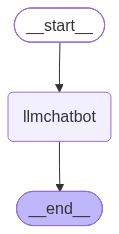

In [13]:
graph_builder.compile()

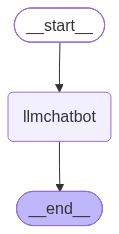

In [14]:

from IPython.display import Image,display

try:
    graph = graph_builder.compile()
# Phir display karo
    display(Image(graph.get_graph().draw_mermaid_png()))
except:
    pass

In [15]:
responce=graph.invoke({'messages':'mohit payasi who is data science trianer'})
responce['messages'][-1].content

'**Mohit Payasi – Data Science Trainer & Mentor**\n\n| Category | Details |\n|----------|---------|\n| **Full Name** | Mohit Payasi |\n| **Profession** | Data Science Trainer, Mentor, and Consultant |\n| **Specializations** | • Machine Learning & AI <br>• Big Data Analytics <br>• Data Visualization <br>• Statistical Modeling <br>• Deep Learning (TensorFlow, PyTorch) |\n| **Education** | • B.Tech / M.S. in Computer Science / Statistics (exact degree varies by profile) <br>• Certifications: <br>\u2003– Google Cloud Data Engineer <br>\u2003– AWS Certified Data Analytics <br>\u2003– Coursera Specializations (e.g., Applied Data Science, Machine Learning) |\n| **Career Highlights** | • **Senior Data Scientist** at a leading tech firm (e.g., Accenture, IBM, or a top startup) <br>• **Lead Instructor** at prominent online learning platforms (Coursera, Udemy, DataCamp) <br>• **Workshop Facilitator** for industry conferences (PyCon, Strata, AI & Machine Learning Summit) <br>• **Author** of severa

In [16]:
for i in graph.stream({'messages':'data science trianer'}):
    print(i)

{'llmchatbot': {'messages': [AIMessage(content='It looks like you’re interested in **data‑science training** (perhaps as a learner or as a trainer).  \nLet me know which of the following fits your needs (or feel free to add details!):\n\n| What you’re looking for | Why it matters | Quick start |\n|-------------------------|----------------|-------------|\n| **1. Become a data‑science trainer** | You’ll need deep subject‑matter knowledge, pedagogical skills, and a portfolio of workshops. | • Master the core stack (Python/R, SQL, ML, statistics).  <br>• Take a teaching‑methods course (Coursera “Teaching and Learning in Higher Education”, Udemy “Teaching Data Science”).  <br>• Build a “trainer” portfolio: 5‑10 short modules, recorded demos, and a lesson plan. |\n| **2. Find a data‑science training program** | You want a structured curriculum to upskill yourself or a team. | • **Online bootcamps**: DataCamp, DataQuest, Udacity “Data Scientist Nanodegree”, Coursera “Applied Data Science Spe

In [17]:
for i in graph.stream({'messages':'data science trianer'}):
    for value in i.values():
        print(value['messages'][-1].content)

It looks like you’re interested in a **data science trainer**—whether you’re looking to find one, become one, or design a training program. Could you let me know which of these you’re after? For example:

| What you might want | What you’d need to know |
|---------------------|------------------------|
| **Find a trainer** | Location, expertise (e.g., machine learning, Python, statistics), cost, format (online/offline) |
| **Become a trainer** | Key teaching skills, curriculum design, industry experience, certifications |
| **Design a training program** | Target audience (beginners, intermediate, advanced), duration, modules, hands‑on labs, assessment methods |

Let me know which direction you’d like to go (or anything else you have in mind), and I’ll tailor the information accordingly!


In [18]:
# build react

# chat bot with tool

In [19]:
import os
from dotenv import load_dotenv
load_dotenv()  # .env file load karo
os.environ['TAVILY_API_KEY'] = os.getenv('TAVILY_API_KEY')

In [20]:

from langchain_tavily  import TavilySearch

In [21]:
tool= TavilySearch(max_results=7)

In [22]:
def multiply(a:int,b:int):
    """ a will be integer, b b will bw integer, 
    and you have to multiply both number and return as integer
    Args:
        a(int): first int
        b(int); second int

    Returns:
        int: output int    
    """
    




In [23]:
tool=[tool, multiply]
model_with_tool=model.bind_tools(tool)

In [24]:
from langgraph.graph import StateGraph,START,END

from langgraph.prebuilt import ToolNode

from langgraph.prebuilt import tools_condition
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)

builder.add_edge('tools',END)
graph=builder.compile()


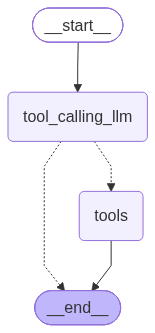

In [25]:
def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)

builder.add_edge('tools',END)
builder.compile()

In [26]:
graph.invoke({'messages':'what is the recent news of ai and find 5 multiply 6 '})

{'messages': [HumanMessage(content='what is the recent news of ai and find 5 multiply 6 ', additional_kwargs={}, response_metadata={}, id='2777d7e6-7bc6-4b02-847d-9bf7a5aec235'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "what is the recent news of ai and find 5 multiply 6". So two tasks: Provide recent news of AI, presumably up-to-date. Also compute 5 * 6. The multiplication is trivial: 30. For the news, we need up-to-date info. The user wants "recent news of ai". We need to browse or search. Use the tavily_search tool. Provide citations. Then answer. Also compute multiplication using function. Use the multiply tool. Let\'s do that.\n\nWe\'ll search for "recent AI news" or "latest AI developments" within recent days. We\'ll use tavily_search with query "AI news 2026" or "latest AI developments" with time_range maybe "day" or "week". Let\'s do a search.', 'tool_calls': [{'id': 'fc_0f02a86d-cc60-4854-a8a4-766f28e8e349', 'function': {'arguments': '{"

In [27]:
for i in graph.stream({'messages':'what is the recent news of ai and find 5 multiply 6 '}):
    for value in i.values():
        print(value['messages'][-1].content)


{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.dallasnews.com/business/economy/article/ai-slows-texas-hiring-hits-recent-grads-hardest-22470276.php", "title": "AI slows Texas hiring, hitting recent grads hardest", "content": "Subscribe\n\nBusiness//Economy\n\n# AI slows Texas hiring, hitting recent grads hardest\n\n## The tech is disproportionately impacting certain jobs and younger workers, researchers at the Dallas Fed told The News.\n\nBy Trevor Bach, Staff Writer\n\nAttendees walk through a military community hiring event hosted by DAV and RecruitMilitary in August at AT&T Stadium in Arlington.\n\nMichael Cuviello/Dallas Morning News\n\nIt’s been the digital elephant in university classrooms, corporate offices and staffing agencies: As AI continues to redefine modern life, what exactly does it mean for people’s jobs? [...] A recent analysis from the Dallas Fed offers new insight on the tech’s impact within Te

In [28]:
# ReAct = Reasoning + Acting

# Yeh ek AI Agent pattern hai jahan LLM pehle sochta hai,
#  phir action leta hai, phir result dekhta hai — aur yeh loop tab tak chalta hai jab tak final
#   answer na mile.

In [30]:
# Question aaya
#     ↓
# 🧠 THOUGHT  → "Mujhe pehle weather API call karni chahiye"
#     ↓
# ⚡ ACTION   → weather_tool("Delhi")
#     ↓
# 👁️ OBSERVATION → "Delhi: 35°C, Sunny"
#     ↓
# 🧠 THOUGHT  → "Ab main answer de sakta hoon"
#     ↓
# ✅ FINAL ANSWER → "Delhi mein aaj 35°C hai aur dhoop hai"

#---------------------------------------------------------------------------------------------------
# feature	               Normal LLM	                  ReAct Agent
# Memory	          ❌ Sirf training data	            ✅ Tools se live data
# Tools use	          ❌ Nahi kar sakta	                ✅ Haan kar sakta hai
# Multi-step	      ❌ Ek shot answer	                ✅ Step by step sochta hai
# Self-correction	  ❌ Nahi	                        ✅ Observation se seekhta hai

In [31]:
from langgraph.graph import StateGraph,START,END

from langgraph.prebuilt import ToolNode

from langgraph.prebuilt import tools_condition
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)
builder.add_edge('tools','tool_calling_llm')
builder.add_edge('tools',END)
graph1=builder.compile()

In [33]:
for i in graph1.stream({'messages':'what is the recent news of ai and find 5 multiply 6 '}):
    for value in i.values():
        print(value['messages'][-1].content)


{"query": "latest AI developments 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.netguru.com/blog/latest-ai-developments-2026", "title": "Latest AI developments 2026: Models, agentic AI, infrastructure", "content": "### What are the latest AI developments this week?\n\nThe latest AI developments this week are Anthropic's agentic AI tool-use update and OpenAI's model routing refinement, both shipped days after August's earlier releases. This is artificial intelligence news worth a full read, not a headline skim, since routing changes affect token cost directly. Check vendor changelogs for a fuller view before adjusting your own pipeline.\n\n### What are the biggest AI breakthroughs of 2026? [...] ### What are the biggest AI breakthroughs of 2026?\n\nThe biggest 2026 breakthroughs were agentic AI systems moving from research demos into production use, plus frontier model gains on large language model benchmarks. According to industry r

In [34]:
# memory implementation of AI agent with langgraph
# LangGraph mein memory ka kaam karta hai Checkpointer — jo har step ka State save karta rehta hai.

In [35]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()
from langgraph.prebuilt import ToolNode

from langgraph.prebuilt import tools_condition
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [model_with_tool.invoke(state["messages"])]}
# 5. Graph build karo
builder = StateGraph(State)
builder.add_node('tool_calling_llm', tool_calling_llm)   #  name + function
builder.add_node('tools', ToolNode(tool))    


builder.add_edge(START, 'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm', tools_condition)
builder.add_edge('tools','tool_calling_llm')
builder.add_edge('tools',END)

graph2=builder.compile(checkpointer=memory)

In [36]:
config= {'configurable':{'thread_id':'mohit_chat_1'}}

graph2.invoke({'messages':'hey my name is mohit'},config=config)

{'messages': [HumanMessage(content='hey my name is mohit', additional_kwargs={}, response_metadata={}, id='29b8828e-c56a-4032-b7b8-f56d89185a76'),
  AIMessage(content='Hi Mohit! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hey my name is mohit". They want to respond. No request for function. Just greet.'}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 380, 'total_tokens': 424, 'completion_time': 0.04528464, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.021683469, 'prompt_tokens_details': None, 'queue_time': 0.308670819, 'total_time': 0.066968109}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e594c51153', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a13395-b7bd-7420-82e5-629a30dba9a2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 380, 'output_tokens': 44, 'total_tokens': 424, 'output_to

In [64]:
graph2.invoke({'messages':'tell me my name'},config=config)

{'messages': [HumanMessage(content='hey my name is mohit', additional_kwargs={}, response_metadata={}, id='481cb35a-4b1b-4f86-87c9-43468dad2e86'),
  AIMessage(content='Hello Mohit! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hey my name is mohit". We should respond. Probably greet and ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 46, 'prompt_tokens': 380, 'total_tokens': 426, 'completion_time': 0.048088657, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.019976244, 'prompt_tokens_details': None, 'queue_time': 0.209211404, 'total_time': 0.068064901}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a8c584dda7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12e18-ef42-7e72-8249-027c43a59b5b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 380, 'output_tokens': 46, 'total_tokens': 426, 'out

In [65]:
for i in graph2.stream({'messages':'AI is dengor my name is mohit and find 5 multiply 6  what is weather of london'},config=config):
    for value in i.values():
        print(value['messages'][-1].content)


{"query": "current weather London", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "Weather in London", "url": "https://www.weatherapi.com/", "content": "{'location': {'name': 'London', 'region': 'City of London, Greater London', 'country': 'United Kingdom', 'lat': 51.5171, 'lon': -0.1062, 'tz_id': 'Europe/London', 'localtime_epoch': 1791774754, 'localtime': '2026-10-12 04:12'}, 'current': {'last_updated_epoch': 1791774000, 'last_updated': '2026-10-12 04:00', 'temp_c': 12.8, 'temp_f': 55.0, 'is_day': 0, 'condition': {'text': 'Overcast', 'icon': '//cdn.weatherapi.com/weather/64x64/night/122.png', 'code': 1009}, 'wind_mph': 7.2, 'wind_kph': 11.5, 'wind_degree': 148, 'wind_dir': 'SSE', 'pressure_mb': 1014.0, 'pressure_in': 29.93, 'precip_mm': 0.0, 'precip_in': 0.0, 'humidity': 82, 'cloud': 89, 'feelslike_c': 10.8, 'feelslike_f': 51.4, 'windchill_c': 11.7, 'windchill_f': 53.1, 'heatindex_c': 12.8, 'heatindex_f': 55.0, 'dewpoint_c': 9.8, 'dewpoint_f': 49.5

In [66]:
for i in graph2.stream({'messages':'AI is dengor, what is my name and find 5 multiply 6  what is weather of london'},config=config):
    for value in i.values():
        print(value['messages'][-1].content)

**Your name**: Mohit  
**5 × 6**: 30  

**Current weather in London** (as of 12 Oct 2026, 04:12 UTC):  
- Temperature: **12.8 °C (55 °F)**  
- Condition: **Overcast**  
- Wind: 7.2 mph (11.5 kph) from the SSE  
- Humidity: 82 %  
- Feels‑like: 10.8 °C (51 °F)  
- No precipitation expected at the moment.


In [ ]:
# # streaming

# ### Function: `Streaming Execution (stream & astream)`
# * **Purpose**: LangGraph me real-time response aur node updates receive karne ke liye 
# stream()` (synchronous) aur `astream()` (asynchronous) methods ka use hota hai.
# * **Parameters**:
#   - `input` (`dict`): State inputs jaise `{'messages': [...]}`.
#   - `config` (`dict`): `thread_id` aur checkpoint configuration.
#   - `stream_mode` (`str`): `'updates'` (sirf latest node update), `'values'` (full state), 
#   ya `'messages'` (token-by-token output).
# * **Return**: Generator/AsyncGenerator jo har step par state chunk yield karta hai.


LangGraph mein 3 common stream modes hote hain:

stream_mode="updates" (Default):
Har node execute hone par sirf usi node ka output/update return hota hai.
Example: {'tool_calling_llm': {'messages': [...]}}


stream_mode="values":
Har step ke baad poori State ki current snapshot return hoti hai.
History aur complete message list dekhne ke liye best hai.


stream_mode="messages":
LLM ke tokens word-by-word (token-by-token) stream hote hain (Chat UI ke typing effect ke liye).

In [68]:
from langgraph.checkpoint.memory import MemorySaver
memory= MemorySaver()

def superbot(state:State):
    return {'messages':[model_with_tool.invoke(state['messages'])]}

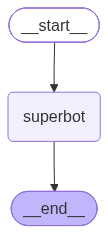

In [69]:
graph= StateGraph(State)

graph.add_node('superbot',superbot)
graph.add_edge(START,'superbot')

graph.add_edge('superbot',END)

graph.compile(checkpointer=memory)

In [70]:
config = {'configurable': {'thread_id': "1"}}
# Option 1 - string bhi chalega agar graph2 use kar rahe ho (LangGraph internally handle karta hai)
graph2.invoke({'messages': 'Hi my name is mohit payasi and i like cricket'}, config=config)
# Option 2 - Pure safe format
graph2.invoke({'messages': [('user', 'Hi my name is mohit payasi and i like cricket')]}, config=config)


{'messages': [HumanMessage(content='Hi my name is mohit payasi and i like cricket', additional_kwargs={}, response_metadata={}, id='8643b381-6959-4d40-b096-3377d8f90b47'),
  AIMessage(content='Hello Mohit! It’s great to meet a cricket fan. How do you like to follow the game—watch live matches, read about the stats, or play any cricket video games? If there’s anything cricket‑related you’d like to chat about, just let me know!', additional_kwargs={'reasoning_content': 'The user says: "Hi my name is mohit payasi and i like cricket". Probably just greeting. We can respond with a friendly reply. No request.'}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 386, 'total_tokens': 486, 'completion_time': 0.102790435, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.018783936, 'prompt_tokens_details': None, 'queue_time': 0.30814622, 'total_time': 0.121574371}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_d3e146e1a5', 'servic

In [72]:
config={'configurable':{'thread_id':"3"}}
for chunk in graph2.stream({'messages':"my name  is mohit and i like cricket"},config=config,stream_mode='updates'):
    print(chunk)

{'tool_calling_llm': {'messages': [AIMessage(content="Nice to meet you, Mohit! Cricket is such an exciting sport. Do you have a favorite team or player you follow? Or maybe there's a particular format—Test, ODI, or T20—that you enjoy more? Let me know, and we can chat more about it!", additional_kwargs={'reasoning_content': 'The user says "my name is mohit and i like cricket". Likely they want a response. Probably respond politely, ask about cricket, maybe ask which team. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 105, 'prompt_tokens': 384, 'total_tokens': 489, 'completion_time': 0.124285465, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.027172874, 'prompt_tokens_details': None, 'queue_time': 0.383383907, 'total_time': 0.151458339}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12e36-172d

In [73]:
config={'configurable':{'thread_id':"3"}}
for chunk in graph2.stream({'messages':"my name  is mohit and i like cricket"},config=config,stream_mode='values'):
    print(chunk)

{'messages': [HumanMessage(content='my name  is mohit and i like cricket', additional_kwargs={}, response_metadata={}, id='4cef9976-bc57-40c0-9dbe-f408cebfe202'), AIMessage(content="Nice to meet you, Mohit! Cricket is such an exciting sport. Do you have a favorite team or player you follow? Or maybe there's a particular format—Test, ODI, or T20—that you enjoy more? Let me know, and we can chat more about it!", additional_kwargs={'reasoning_content': 'The user says "my name is mohit and i like cricket". Likely they want a response. Probably respond politely, ask about cricket, maybe ask which team. No tool needed.'}, response_metadata={'token_usage': {'completion_tokens': 105, 'prompt_tokens': 384, 'total_tokens': 489, 'completion_time': 0.124285465, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.027172874, 'prompt_tokens_details': None, 'queue_time': 0.383383907, 'total_time': 0.151458339}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_5979a0e1b

In [75]:
config={'configurable':{'thread_id':"4"}}
for chunk in graph2.stream({'messages':"my name  is mohit and i like cricket"},config=config,stream_mode='updates'):
    print(chunk)

{'tool_calling_llm': {'messages': [AIMessage(content='Hey Mohit! It’s great to hear you’re into cricket. Do you have a favorite team or player? Or maybe you’d like to chat about the latest matches, learn some cricket trivia, or even get tips on playing? Let me know what you’re interested in!', additional_kwargs={'reasoning_content': 'User repeats same statement. Likely wants conversation or maybe ask question? We can respond acknowledging and ask follow-up.'}, response_metadata={'token_usage': {'completion_tokens': 89, 'prompt_tokens': 455, 'total_tokens': 544, 'completion_time': 0.091198872, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.037279451, 'prompt_tokens_details': {'cached_tokens': 256}, 'queue_time': 0.337104449, 'total_time': 0.128478323}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e189667b30', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12e38-203c-71e0-b7c7-1cb

In [ ]:

for chunk in graph2.stream({'messages':"and i also like football"},config=config,stream_mode='values'):
    print(chunk)

{'messages': [HumanMessage(content='my name  is mohit and i like cricket', additional_kwargs={}, response_metadata={}, id='8fd0f644-e89d-4fbe-b132-b3a4f9f09ca0'), AIMessage(content='Hey Mohit! It’s great to hear you’re into cricket. Do you have a favorite team or player? Or maybe you’d like to talk about the latest matches or learn something new about the game? Let me know what you’re interested in!', additional_kwargs={'reasoning_content': 'User says: "my name is mohit and i like cricket". Likely wants some response. We can respond with friendly. No request for tool.'}, response_metadata={'token_usage': {'completion_tokens': 92, 'prompt_tokens': 384, 'total_tokens': 476, 'completion_time': 0.096949768, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.019206796, 'prompt_tokens_details': None, 'queue_time': 0.379344165, 'total_time': 0.116156564}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_f102a3179c', 'service_tier': 'on_demand', 'finish_reason

In [ ]:
#async
config={'configurable':{'thread_id':"5"}}

async for chunk in graph2.astream_events({'messages':"and i also like football"},config=config, version='v2'):
    print(chunk)



{'event': 'on_chain_start', 'data': {'input': {'messages': 'and i also like football'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a12e3b-06b0-7a40-8a71-baaee16301ba', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='and i also like football', additional_kwargs={}, response_metadata={}, id='182271ef-5349-49ab-b3f6-5b5152106d5c')]}}, 'name': 'tool_calling_llm', 'tags': ['graph:step:1'], 'run_id': '01a12e3b-06b3-74e3-8527-e8b439c0f42c', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'tool_calling_llm', 'langgraph_triggers': ('branch:to:tool_calling_llm',), 'langgraph_path': ('__pregel_pull', 'tool_calling_llm'), 'langgraph_checkpoint_ns': 'tool_calling_llm:95960b17-5e9a-f981-b2dd-edd2edcb586a'}, 'parent_ids': ['01a12e3b-06b0-7a40-8a71-baaee16301ba']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[Hum

In [78]:
# human  feedback in the loop

In [82]:
from typing import Annotated
from langchain_tavily import tavily_search

from langchain_core.tools import tool

from langgraph.graph import StateGraph,START,END

from langgraph.graph.message import add_messages
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition

from langgraph.types import Command, interrupt # to interrup workflow to provide human feedback

In [93]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.tools import tool
from langchain_tavily import TavilySearch
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt

# 1. State Definition
class State(TypedDict):
    messages: Annotated[list, add_messages]

# 2. Human Assistance Tool
@tool
def human_assistance(query: str) -> str:
    """Request assistance from a human."""
    human_response = interrupt({"query": query})
    # Safe handling: agar dict ho toh 'data', warna direct string return kare
    if isinstance(human_response, dict):
        return human_response.get("data", str(human_response))
    return str(human_response)

# 3. Tools Setup
tavily_tool = TavilySearch(max_results=3)
tools_list = [tavily_tool, human_assistance]

# Model binding
model_with_tools = model.bind_tools(tools_list)

# 4. Chatbot Node
def chat_bot(state: State):
    # Groq token limit se bachne ke liye latest messages pass karein
    message = model_with_tools.invoke(state["messages"][-8:])
    return {"messages": [message]}

# 5. Graph Building
builder = StateGraph(State)

builder.add_node("chatbot", chat_bot)
builder.add_node("tools", ToolNode(tools=tools_list))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")

# 6. Memory & Compilation (Fix: Variable mein store kiya)
memory = MemorySaver()
graph4=builder.compile(checkpointer=memory)


In [97]:
user_input='i need your guidence to became AI Engineer give me idea'
config= {'configurable':{'thread_id':1}}

results=graph4.stream({"messages":user_input},config=config,stream_mode='values')
for result in results:
    if 'messages' in result:
        result['messages'][-1].pretty_print()

================================ Human Message =================================

i need your guidence to became AI Engineer give me idea
================================== Ai Message ==================================

## 🚀 Quick‑Start Guide to Becoming an **AI Engineer**

> **Goal:** Build a clear, actionable “to‑do” list that takes you from **zero knowledge** to a *portfolio‑ready* AI Engineer in **12–18 months**.

---

## 1️⃣ Core Pillars (What to Learn)

| Pillar | Why It Matters | Key Resources | Mini‑Project |
|--------|----------------|---------------|--------------|
| **Programming** | Every AI job starts with code. | *Automate the Boring Stuff* (Python), *Python for Data Analysis* | Build a “Hello World” Jupyter notebook that pulls data from a public API. |
| **Mathematics** | Models are built on linear algebra, calculus, probability. | *3Blue1Brown* YouTube series, *Mathematics for Machine Learning* (Coursera) | Write a Python script that visualizes a 3‑D Gaussian. |
| **Dat